# Cassava Leaf Disease Classifier: Machine Learning Cycle (MLOps)

This notebook is the **offline** part of the ML cycle. It builds on the Intro to ML summative (cassava leaf
disease classification) and turns its best model (E11: frozen MobileNetV2 + small trained head with softened
class weights) into a model that the deployed app can serve and retrain.

| Step | Section |
|---|---|
| 1. Data acquisition | Section 2 (Kaggle API) |
| 2. Data processing | Sections 3 to 6 (checks, visualisations, split, preprocessing pipeline) |
| 3. Model creation | Section 7 (transfer learning with optimisation) |
| 4. Model testing | Sections 8 and 9 (6 metrics, confusion matrix, ROC curves, prediction function) |
| 5. Model retraining | Section 11 (the saved model is reloaded as the pretrained starting point) |
| 6. API | `api/main.py` (FastAPI), served by Docker; this notebook saves the files it needs |

**How to run:** in Google Colab with a GPU (Runtime > Change runtime type > T4 GPU). Add your Kaggle API token
as a Colab secret named `KAGGLE_API_TOKEN` (key icon on the left). Then Runtime > Run all. Takes about 15 minutes.

## 1. Setup
Get the project code (the `src/` package), install packages and fix random seeds so the results can be reproduced.

In [8]:
import os, sys, json, random, shutil
from pathlib import Path

REPO_URL = "https://github.com/rachealA924/Racheal_Resty_Akello-Summative_MLOP.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # 1. First go back to a safe root directory to prevent getcwd errors
    os.chdir("/content")

    # 2. Clean up any broken folder
    dest_path = Path("/content/cassava-mlops")
    if dest_path.exists():
        shutil.rmtree(dest_path)

    # 3. Clone fresh while working from /content
    !git clone {REPO_URL} /content/cassava-mlops

    # 4. Now safely step into the cloned repository
    os.chdir("/content/cassava-mlops")
    !pip install -q kaggle
elif Path.cwd().name == "notebook":
    os.chdir("..")                         # run from the repo root when opened locally
sys.path.insert(0, os.getcwd())
print("Working directory contents:", os.listdir(os.getcwd()))

Cloning into '/content/cassava-mlops'...
remote: Enumerating objects: 31, done.
remote: Counting objects: 100% (31/31), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 31 (delta 0), reused 31 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (31/31), 38.16 KiB | 583.00 KiB/s, done.
Working directory contents: ['docker-compose.yml', '.dockerignore', 'notebook', 'README.md', 'Dockerfile', '.gitignore', '.git', 'models', 'nginx.conf', 'src', 'results', 'requirements.txt', 'locustfile.py', 'api', 'data', 'ui', 'requirements-dev.txt', 'scripts']


In [9]:
import os, sys, random
from pathlib import Path

# Ensure the cloned repository root is in python's search path
repo_path = "/content/cassava-mlops"
if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf, keras

from src.config import CLASS_NAMES, CLASS_DESCRIPTIONS, IMG_SIZE, SEED, DATA_DIR, MODELS_DIR, TRAIN_DIR, TEST_DIR
from src.preprocessing import load_image, load_batch, image_statistics, list_labelled_images
from src.model import (build_model, split_model, extract_features, train_head, soft_class_weights,
                       compute_metrics, save_model, load_model)

random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
FIG_DIR = Path("notebook/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)

def sample_per_class(d, n, seed=SEED):
    """Up to n random rows of each class (works the same in every pandas version)."""
    return pd.concat([g.sample(min(len(g), n), random_state=seed) for _, g in d.groupby("class")])

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data acquisition
The data is the Kaggle competition **Cassava Leaf Disease Classification**: 21,397 photos of cassava leaves taken
by farmers in Uganda, each labelled with one of five classes. It is downloaded with the Kaggle API, using a token
stored as a Colab secret (never written in the notebook). The download is about 5.8 GB.

For a quick offline test of this notebook, set the environment variable `CASSAVA_LOCAL_DATA` to a folder with the
same layout (`train.csv`, `train_images/`, `label_num_to_disease_map.json`).

In [10]:
RAW = Path(os.getenv("CASSAVA_LOCAL_DATA", "/content/raw"))
if not (RAW / "train.csv").exists():
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    RAW.mkdir(parents=True, exist_ok=True)
    !kaggle competitions download -c cassava-leaf-disease-classification -p {RAW}
    !cd {RAW} && unzip -q -o cassava-leaf-disease-classification.zip -x "train_tfrecords/*" "test_tfrecords/*"
print(sorted(p.name for p in RAW.iterdir()))

100% 5.76G/5.76G [01:23<00:00, 74.1MB/s]

['cassava-leaf-disease-classification.zip', 'label_num_to_disease_map.json', 'sample_submission.csv', 'test_images', 'train.csv', 'train_images']


In [11]:
df = pd.read_csv(RAW / "train.csv")
label_map = json.load(open(RAW / "label_num_to_disease_map.json"))
df["class"] = df["label"].map(lambda i: CLASS_NAMES[i])
df["path"] = df["image_id"].map(lambda f: str(RAW / "train_images" / f))
print("Images:", len(df))
print("Kaggle label map:", label_map)
df.head()

Images: 21397
Kaggle label map: {'0': 'Cassava Bacterial Blight (CBB)', '1': 'Cassava Brown Streak Disease (CBSD)', '2': 'Cassava Green Mottle (CGM)', '3': 'Cassava Mosaic Disease (CMD)', '4': 'Healthy'}


,image_id,label,class,path
0,1000015157.jpg,0,CBB,/content/raw/train_images/1000015157.jpg
1,1000201771.jpg,3,CMD,/content/raw/train_images/1000201771.jpg
2,100042118.jpg,1,CBSD,/content/raw/train_images/100042118.jpg
3,1000723321.jpg,1,CBSD,/content/raw/train_images/1000723321.jpg
4,1000812911.jpg,3,CMD,/content/raw/train_images/1000812911.jpg


## 3. Data quality checks
Every file is checked once: does it exist, can it be opened, and what size is it? Duplicate image ids are also checked.

In [12]:
from PIL import Image
sizes, bad = {}, []
for p in df["path"]:
    try:
        with Image.open(p) as im:
            im.verify()
            sizes[im.size] = sizes.get(im.size, 0) + 1
    except Exception:
        bad.append(p)
print("Image sizes (width, height) -> count:", sizes)
print("Unreadable files:", len(bad))
print("Duplicate image ids:", df["image_id"].duplicated().sum())
print("Missing labels:", df["label"].isna().sum())
df = df[~df["path"].isin(bad)].drop_duplicates("image_id").reset_index(drop=True)
print("Images kept:", len(df))

Image sizes (width, height) -> count: {(800, 600): 21397}
Unreadable files: 0
Duplicate image ids: 0
Missing labels: 0
Images kept: 21397


## 4. Exploratory analysis and data visualisations
### 4.1 Class balance

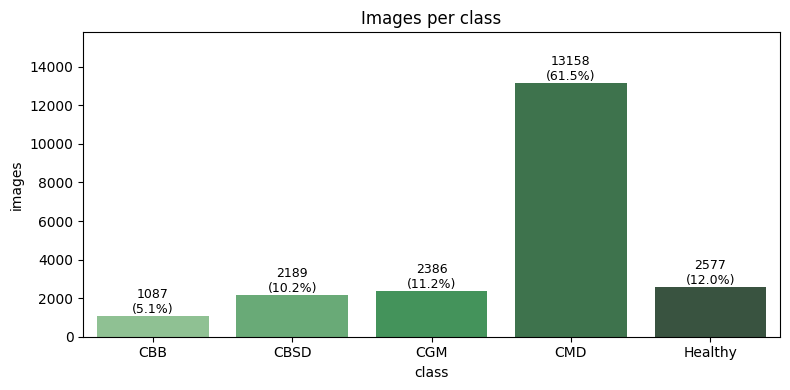

In [13]:
counts = df["class"].value_counts().reindex(CLASS_NAMES)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette="Greens_d", legend=False, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v}\n({v / len(df):.1%})", ha="center", va="bottom", fontsize=9)
ax.set(title="Images per class", ylabel="images"); ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout(); plt.savefig(FIG_DIR / "class_balance.png", dpi=150); plt.show()

**Interpretation:** the classes are heavily imbalanced. Cassava Mosaic Disease (CMD) is the large majority
(about 61% in the Kaggle data) and Cassava Bacterial Blight (CBB) the rarest (about 5%). A model that always said
"CMD" would already reach about 61% accuracy while being useless for the other diseases. So the model uses
**class weights** during training, and it is judged with **macro precision, recall and F1**, which give every class
the same importance, not just accuracy.

### 4.2 Example images

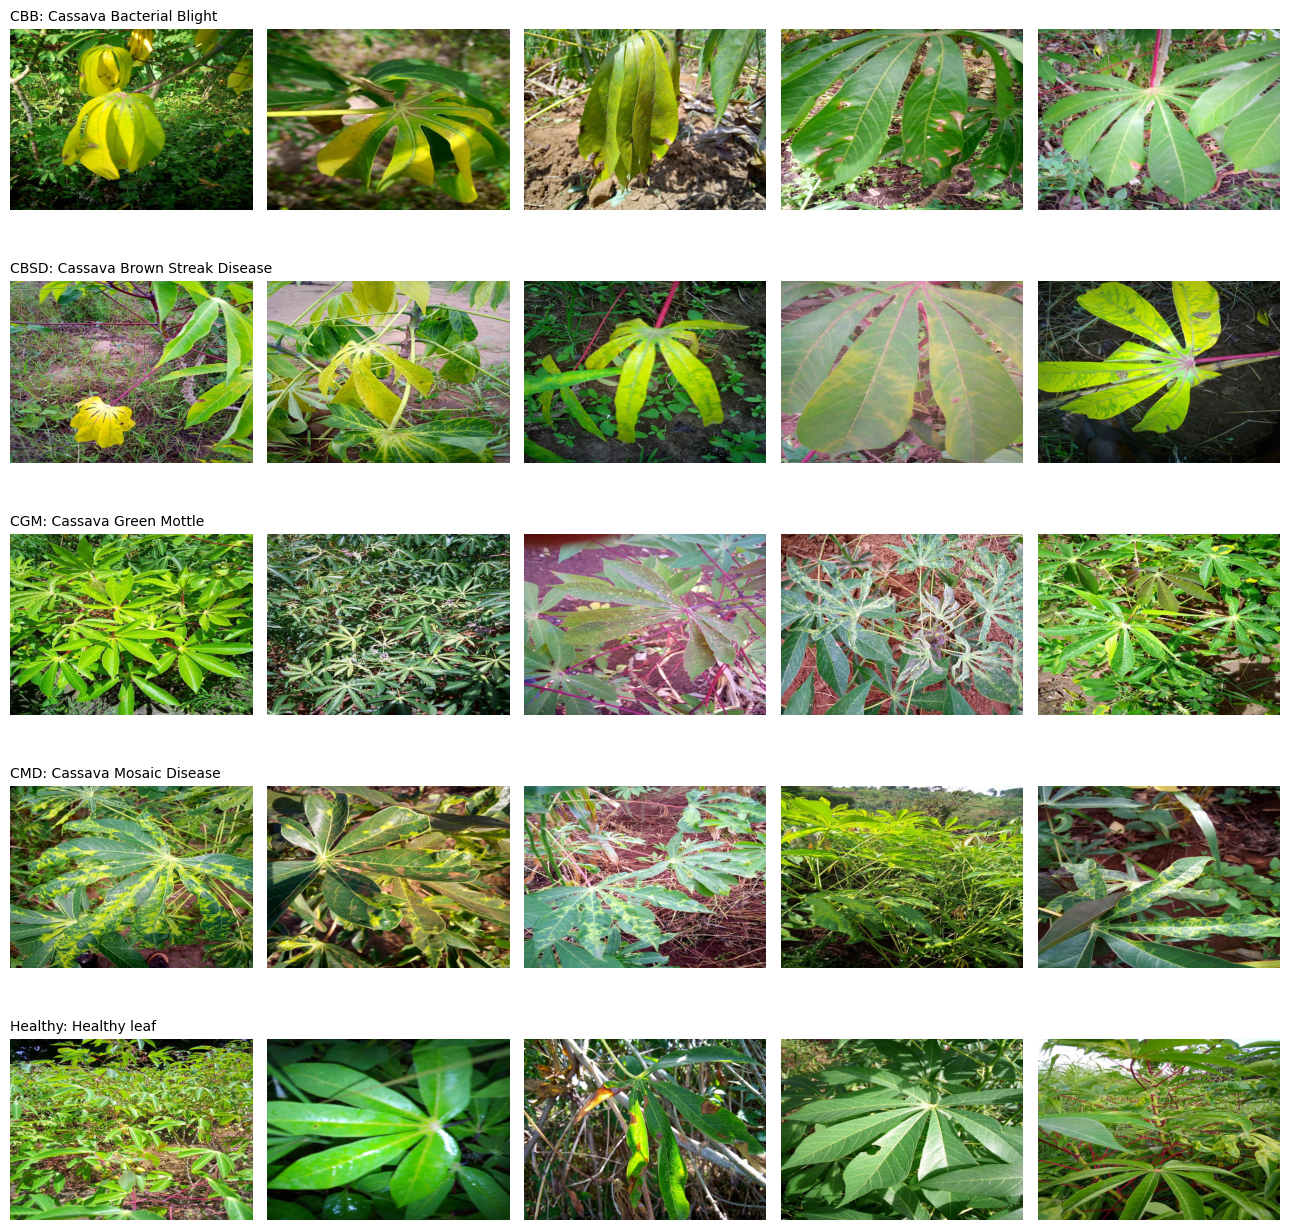

In [14]:
fig, axes = plt.subplots(len(CLASS_NAMES), 5, figsize=(13, 13))
for r, c in enumerate(CLASS_NAMES):
    for k, p in enumerate(df[df["class"] == c].sample(5, random_state=SEED)["path"]):
        axes[r, k].imshow(Image.open(p)); axes[r, k].axis("off")
    axes[r, 0].set_title(f"{c}: {CLASS_DESCRIPTIONS[c]}", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(FIG_DIR / "examples.png", dpi=110); plt.show()

### 4.3 Image features
Images have no columns, so four simple, explainable features are measured on 150 random images per class:

* **Brightness**: mean grayscale pixel value (0 = black, 255 = white)
* **Greenness**: G / (R + G + B), the share of green in the colour
* **Yellow / brown share**: the share of pixels that look yellow or brown (a sign of discoloured tissue)
* **Contrast**: standard deviation of grayscale pixels (texture, spots, patches)

The deployed app shows the same four features on its *Data insights* page.

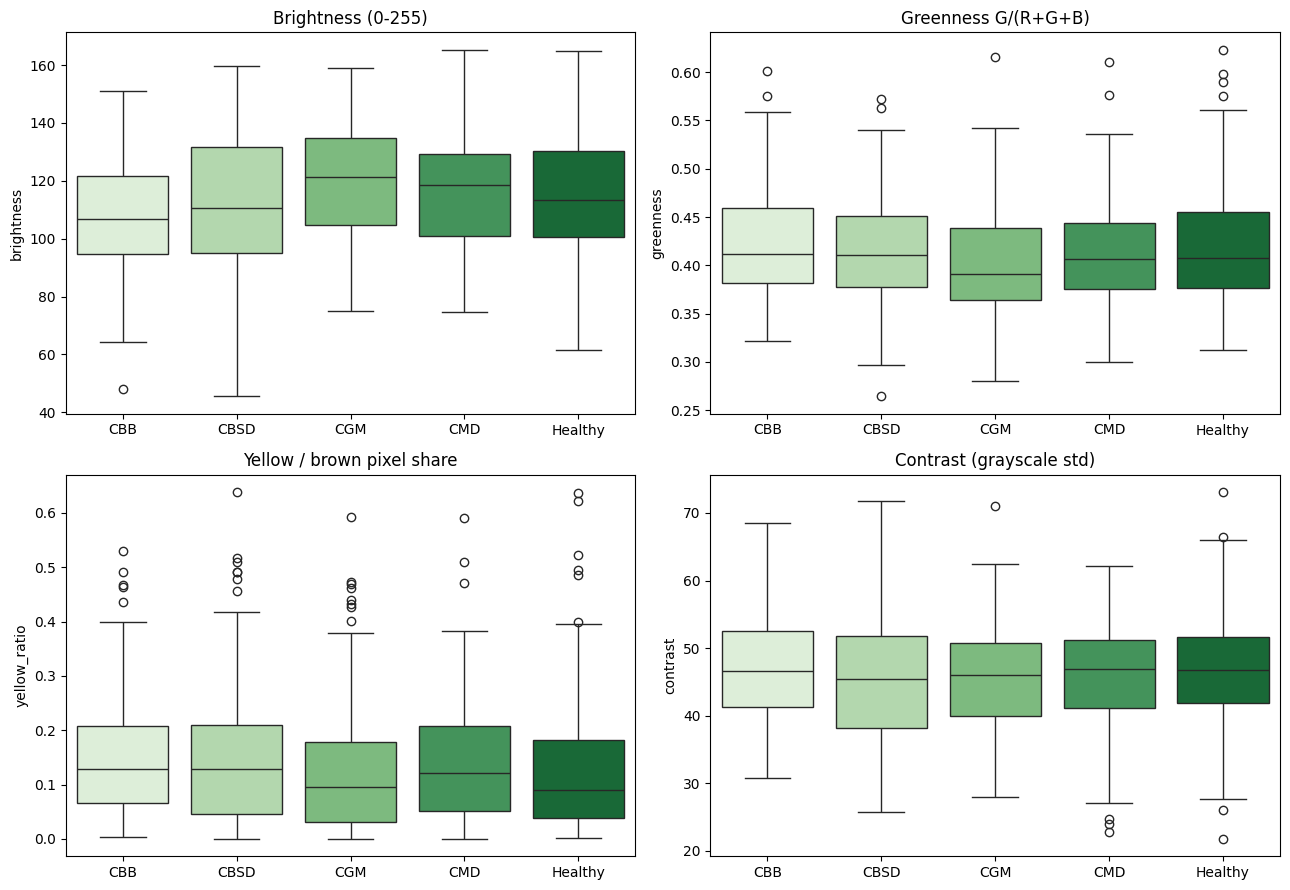

,brightness,greenness,yellow_ratio,contrast
class,,,,
CBB,108.098,0.423,0.149,47.077
CBSD,112.919,0.417,0.151,45.253
CGM,120.072,0.405,0.125,45.849
CMD,116.452,0.413,0.144,46.136
Healthy,115.062,0.420,0.131,46.708


In [15]:
sample = sample_per_class(df, 150)
feats = pd.DataFrame([image_statistics(p) for p in sample["path"]])
feats["class"] = sample["class"].values

FEATURES = {"brightness": "Brightness (0-255)", "greenness": "Greenness G/(R+G+B)",
            "yellow_ratio": "Yellow / brown pixel share", "contrast": "Contrast (grayscale std)"}
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (f, title) in zip(axes.ravel(), FEATURES.items()):
    sns.boxplot(data=feats, x="class", y=f, order=CLASS_NAMES, hue="class", palette="Greens", legend=False, ax=ax)
    ax.set(title=title, xlabel="")
plt.tight_layout(); plt.savefig(FIG_DIR / "image_features.png", dpi=150); plt.show()
feats.groupby("class")[list(FEATURES)].mean().reindex(CLASS_NAMES).round(3)

In [16]:
# The same interpretation function the deployed app uses, applied to these numbers
from src.insights import _interpret
for f in FEATURES:
    means = feats.groupby("class")[f].mean().to_dict()
    print(f"{FEATURES[f]}:\n  {_interpret(f, means)}\n")

Brightness (0-255):
  CGM photos are the brightest on average (120) and CBB the darkest (108). Brightness mostly reflects lighting and background in the field, not the disease, so the model should not rely on it. This is why every image is rescaled the same way and why mixed lighting in new uploads is useful training data.

Greenness G/(R+G+B):
  CBB leaves are the greenest (0.423) and CGM the least green (0.405). CBSD, CGM, CMD are less green than Healthy (0.420), which fits disease destroying chlorophyll. The differences are small, so colour alone cannot separate the classes.

Yellow / brown pixel share:
  CBSD has the largest share of yellow or brown pixels (15.1%) and CGM the smallest (12.5%). Healthy leaves sit at 13.1%. Yellowing and browning are visible symptoms of mosaic, mottle and streak diseases, so this feature carries real signal. Some yellow also comes from soil and dry grass in the background.

Contrast (grayscale std):
  CBB images have the most contrast (47.1) and CBSD

**Interpretation (what story do the features tell?)**

1. **Brightness** mostly reflects how and where the photo was taken (sun, shade, background), not the disease.
   The ranges of all classes overlap heavily. This tells us the model must not depend on lighting, which is why
   every image is rescaled the same way and why photos with varied lighting are valuable when retraining.
2. **Greenness** is a direct symptom: diseases damage chlorophyll, so infected leaves tend to be less green than
   healthy ones. The boxes overlap, so colour on its own cannot separate the classes.
3. **Yellow / brown share** captures the visible yellowing (mosaic, mottle) and brown lesions (streak, blight).
   It separates Healthy from the diseased classes better than brightness does, but soil and dry grass in the
   background add noise.
4. **Contrast** measures texture. Mosaic and blight produce patchy, spotted leaves.

Overall, simple colour statistics hint at the disease but overlap a lot. Telling the five classes apart needs
**shape and texture patterns**, which is why a convolutional network pretrained on ImageNet (MobileNetV2) is used.

## 5. Train / validation / test split
A stratified 70 / 15 / 15 split with seed 42, the same as the summative, so every split keeps the class proportions.
The **test set is only used for the final evaluation**; the validation set drives early stopping.

In [17]:
from sklearn.model_selection import train_test_split
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:<11} {len(d):>6} images |", d["class"].value_counts(normalize=True).reindex(CLASS_NAMES).round(3).to_dict())

train        14977 images | {'CBB': 0.051, 'CBSD': 0.102, 'CGM': 0.112, 'CMD': 0.615, 'Healthy': 0.12}
validation    3210 images | {'CBB': 0.051, 'CBSD': 0.102, 'CGM': 0.112, 'CMD': 0.615, 'Healthy': 0.121}
test          3210 images | {'CBB': 0.051, 'CBSD': 0.102, 'CGM': 0.112, 'CMD': 0.615, 'Healthy': 0.12}


## 6. Preprocessing pipeline
Each image is: decoded as RGB → resized to 224 × 224 → scaled from 0..255 to -1..1 (the range MobileNetV2 was
trained on). The scaling is a `Rescaling` layer **inside** the model, so the API, the notebook and retraining can
never forget it or do it differently.

`tf.data` reads and resizes images in parallel and prefetches batches, so the GPU is never waiting for the disk.

In [18]:
AUTOTUNE = tf.data.AUTOTUNE
def read_image(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

def make_ds(d, batch=64):
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["label"].values))
    return ds.map(read_image, num_parallel_calls=AUTOTUNE).batch(batch).prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df), make_ds(val_df), make_ds(test_df)
x, y = next(iter(train_ds))
print("Batch:", x.shape, "| pixel range", float(tf.reduce_min(x)), "to", float(tf.reduce_max(x)), "| labels", y.shape)

Batch: (64, 224, 224, 3) | pixel range 0.0 to 255.0 | labels (64,)


## 7. Model creation
**Transfer learning.** MobileNetV2 was pretrained on 1.4 million ImageNet photos, so it already recognises edges,
textures and shapes. Its weights are **frozen**, and only a small head is trained on top of it:

`Rescaling → MobileNetV2 (frozen) → GlobalAveragePooling (1,280 features) → Dense 256 ReLU + L2 → Dropout 0.3 → Dense 5 softmax`

**Optimisation techniques used**
* a **pretrained model** (MobileNetV2, ImageNet weights)
* the **Adam** optimiser
* **L2 regularisation** (1e-4) and **Dropout** (0.3) against overfitting
* **Early stopping** on validation loss, keeping the best epoch
* **ReduceLROnPlateau**: halve the learning rate when validation loss stalls
* **Softened class weights** (square root of balanced weights), the best setting from the summative (E11)

Because the backbone is frozen, every image always gives the same 1,280 features. They are computed **once**,
and then only the head is trained on them. This is much faster and gives the same result as running the whole
network every epoch. Retraining in production uses exactly the same trick.

In [19]:
WEIGHTS = os.getenv("CASSAVA_WEIGHTS", "imagenet")   # "imagenet" normally; None only for offline tests
WEIGHTS = None if WEIGHTS == "none" else WEIGHTS
model = build_model(weights=WEIGHTS)
model.summary(show_trainable=True)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "cassava_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ image (InputLayer)          │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ scale_to_minus1_1           │ (None, 224, 224, 3)   │          0 │   -   │
│ (Rescaling)                 │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenetv2_1.00_224        │ (None, 7, 7, 1280)    │  2,257,984 │   N   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ features                    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ head_dense (Dense)          │ (None, 256)           │    327,936 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ head_dropout (Dropout)      │ (None, 256)           │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ head_output (Dense)         │ (None, 5)             │      1,285 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 2,587,205 (9.87 MB)

 Trainable params: 329,221 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [20]:
feature_extractor, head = split_model(model)
F_train = feature_extractor.predict(train_ds, verbose=1); y_train = train_df["label"].values
F_val   = feature_extractor.predict(val_ds, verbose=1);   y_val   = val_df["label"].values
F_test  = feature_extractor.predict(test_ds, verbose=1);  y_test  = test_df["label"].values
print("Feature matrices:", F_train.shape, F_val.shape, F_test.shape)

235/235 ━━━━━━━━━━━━━━━━━━━━ 83s 255ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 24s 480ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 10s 204ms/step
Feature matrices: (14977, 1280) (3210, 1280) (3210, 1280)


In [21]:
cw = soft_class_weights(y_train)
print("Class weights:", {CLASS_NAMES[k]: round(v, 2) for k, v in cw.items()})
history = train_head(head, F_train, y_train, F_val, y_val, epochs=40, lr=1e-3, patience=5, class_weight=cw)
print("Epochs run:", len(history["loss"]), "| best validation loss:", round(min(history["val_loss"]), 4))

Class weights: {'CBB': 1.98, 'CBSD': 1.4, 'CGM': 1.34, 'CMD': 0.57, 'Healthy': 1.29}
Epochs run: 17 | best validation loss: 0.7961


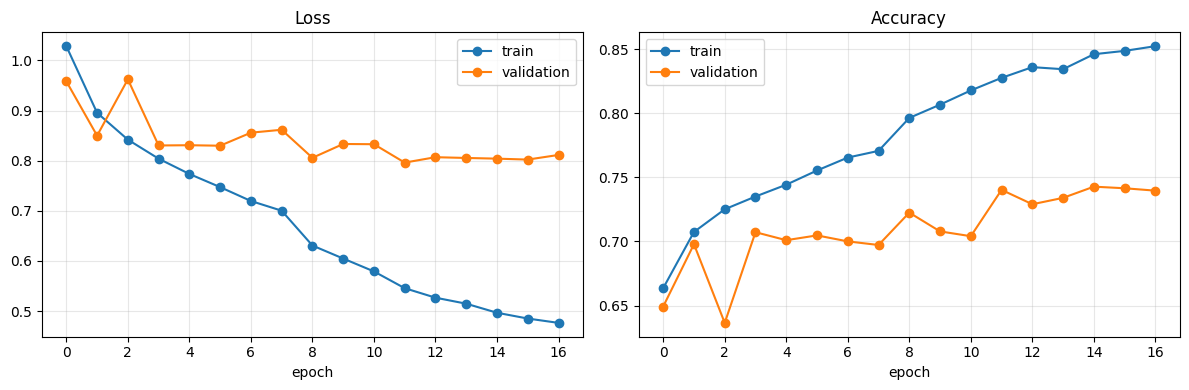

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, m in zip(axes, ["loss", "accuracy"]):
    ax.plot(history[m], marker="o", label="train"); ax.plot(history["val_" + m], marker="o", label="validation")
    ax.set(title=m.capitalize(), xlabel="epoch"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "learning_curves.png", dpi=150); plt.show()

**Reading the learning curves:** if training loss keeps falling while validation loss rises, the model is
overfitting; early stopping restores the epoch with the lowest validation loss, so the saved model is the one
that generalised best. A small gap between the two curves means regularisation and dropout are doing their job.

## 8. Model testing on the held-out test set
Six metrics are reported:
* **Accuracy**: share of correct predictions
* **Loss**: cross-entropy, which also punishes confident wrong answers (lower is better)
* **Precision (macro)**: when the model says "class X", how often it is right, averaged over classes
* **Recall (macro)**: of all leaves of class X, how many the model found, averaged over classes
* **F1 (macro and weighted)**: balance of precision and recall
* **AUC (macro, one-vs-rest)**: how well the probabilities rank the right class above the others

In [23]:
proba_test = head.predict(F_test, verbose=0)
test_metrics = compute_metrics(y_test, proba_test)
summary = {k: test_metrics[k] for k in ["accuracy", "loss", "precision_macro", "recall_macro",
                                         "f1_macro", "f1_weighted", "auc_macro"] if k in test_metrics}
display(pd.Series(summary, name="test set").to_frame())
print(pd.DataFrame(test_metrics["per_class"]).T.round(3).to_string())

,test set
accuracy,0.7299
loss,0.7434
precision_macro,0.5789
recall_macro,0.5703
f1_macro,0.5730
f1_weighted,0.7289
auc_macro,0.8959


              precision  recall  f1-score  support
CBB               0.446   0.460     0.453   163.00
CBSD              0.590   0.520     0.553   329.00
CGM               0.452   0.525     0.486   358.00
CMD               0.863   0.875     0.869  1974.00
Healthy           0.543   0.472     0.505   386.00
accuracy          0.730   0.730     0.730     0.73
macro avg         0.579   0.570     0.573  3210.00
weighted avg      0.730   0.730     0.729  3210.00


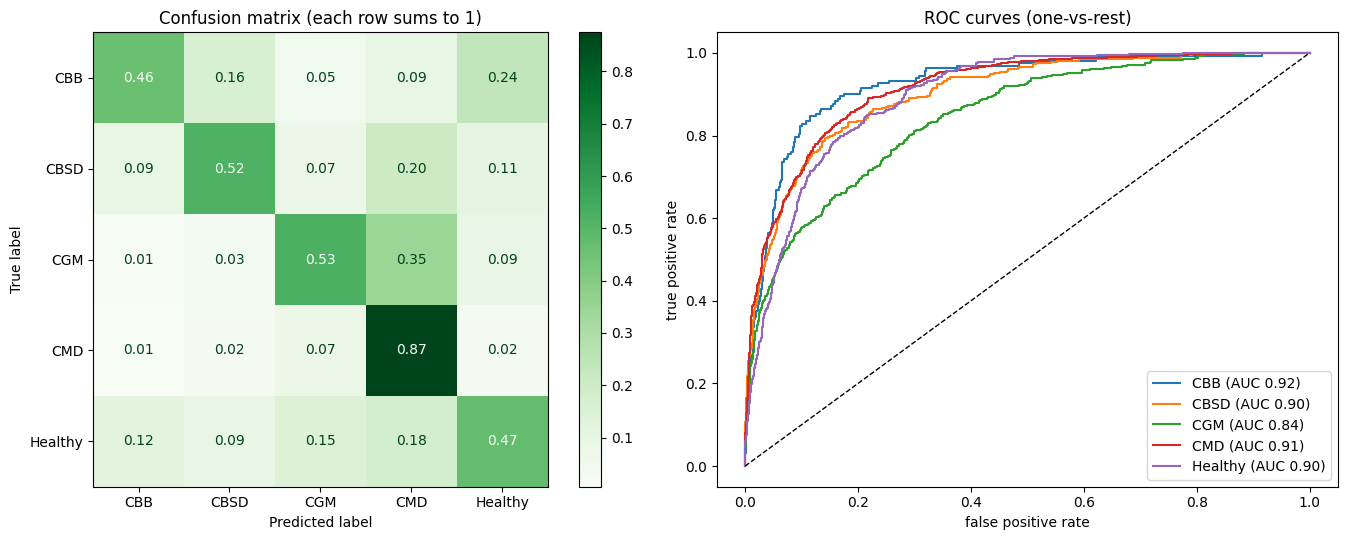

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc
from sklearn.preprocessing import label_binarize
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, proba_test.argmax(1), display_labels=CLASS_NAMES,
                                        normalize="true", values_format=".2f", cmap="Greens", ax=axes[0])
axes[0].set_title("Confusion matrix (each row sums to 1)")
Y = label_binarize(y_test, classes=range(len(CLASS_NAMES)))
for i, c in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(Y[:, i], proba_test[:, i])
    axes[1].plot(fpr, tpr, label=f"{c} (AUC {auc(fpr, tpr):.2f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set(title="ROC curves (one-vs-rest)", xlabel="false positive rate",
                                                     ylabel="true positive rate"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_roc.png", dpi=150); plt.show()

**Interpretation:** the diagonal of the confusion matrix is each class's recall. Look at which classes are most
often confused with CMD: because CMD dominates the training data, borderline leaves get pulled towards it, and the
class weights only partly correct this. These numbers are the baseline that every retrained model is compared to.

## 9. Prediction function
`src/prediction.py` takes one image (path or bytes) and returns the class, a description, the confidence and all five probabilities. The API calls exactly this function.

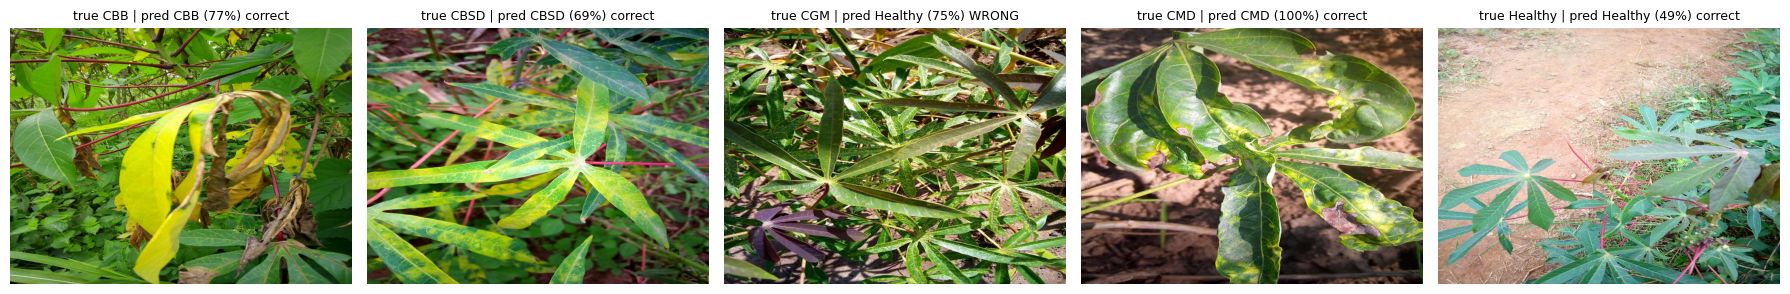

In [25]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
tmp_model_path = MODELS_DIR / "notebook_check.keras"
model.save(tmp_model_path)
from src.prediction import Predictor
predictor = Predictor(tmp_model_path)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, (_, row) in zip(axes, sample_per_class(test_df, 1, seed=1).iterrows()):
    r = predictor.predict(row["path"])
    ok = "correct" if r["label"] == row["class"] else "WRONG"
    ax.imshow(Image.open(row["path"])); ax.axis("off")
    ax.set_title(f"true {row['class']} | pred {r['label']} ({r['confidence']:.0%}) {ok}", fontsize=9)
plt.tight_layout(); plt.show()
tmp_model_path.unlink()

## 10. Save the model and the deployment data
* `models/cassava_mobilenetv2.keras`: the trained model (backbone + head), version 1
* `models/model_metadata.json`: version, test metrics and version history
* `data/train/<class>/`: a **sample** of training images (the full 21k images are too big for GitHub and the
  server). Retraining mixes some of these with newly uploaded images, so the model does not forget old classes.
* `data/test/<class>/`: a fixed, **balanced** test sample (40 per class). The app scores every model version on
  this same set, so versions can be compared fairly. Because it is balanced, its accuracy will be lower than on the
  full (CMD-heavy) test set, and macro F1 is the fairer number.

In [26]:
import shutil
TRAIN_PER_CLASS, TEST_PER_CLASS = 60, 40
for folder in (TRAIN_DIR, TEST_DIR):
    if folder.exists():
        shutil.rmtree(folder)

def export(d, root, per_class):
    picked = sample_per_class(d, per_class)
    for _, row in picked.iterrows():
        out = root / row["class"] / row["image_id"]
        out.parent.mkdir(parents=True, exist_ok=True)
        im = Image.open(row["path"]).convert("RGB"); im.thumbnail((400, 400)); im.save(out, "JPEG", quality=88)
    return picked

export(train_df, TRAIN_DIR, TRAIN_PER_CLASS)
deploy_test = export(test_df, TEST_DIR, TEST_PER_CLASS)

# metrics on the deployed (balanced) test sample, the numbers the app compares versions with
paths, labels = list_labelled_images(TEST_DIR)
X_deploy, _ = load_batch(paths)
deploy_metrics = compute_metrics(labels, model.predict(X_deploy, verbose=0))
for f in ["model_metadata.json", "cassava_mobilenetv2.keras"]:
    (MODELS_DIR / f).unlink(missing_ok=True)
shutil.rmtree(MODELS_DIR / "archive", ignore_errors=True)
version = save_model(model, deploy_metrics, source="notebook",
                     extra={"full_test_set_metrics": summary, "trained_on_images": int(len(train_df)),
                            "epochs_run": len(history["loss"])})
print("Saved model version", version)
print("Deployed test sample:", {k: deploy_metrics[k] for k in ["accuracy", "f1_macro", "loss"]})
print("Full test set:       ", {k: summary[k] for k in ["accuracy", "f1_macro", "loss"]})

Saved model version 1
Deployed test sample: {'accuracy': 0.51, 'f1_macro': 0.4917, 'loss': 1.4496}
Full test set:        {'accuracy': 0.7299, 'f1_macro': 0.573, 'loss': 0.7434}


## 11. Retraining demonstration
This is what the **Retrain** button in the app does, run here step by step:

1. new labelled images are "uploaded": saved, validated and recorded in the SQLite database
2. the **saved model is loaded** as the pretrained starting point (nothing is trained from scratch)
3. the new images (plus a replay sample of old ones) are preprocessed and turned into features
4. the head is fine tuned with a small learning rate (1e-4), early stopping and class weights
5. old and new model are compared on the same test sample, and the new one is promoted only if it is not worse

The "new" images here are 15 per class taken from the **validation** split, which the model has never trained on
and which are separate from the test sample.

In [27]:
from src import database as db
from src.config import UPLOAD_DIR
from src.preprocessing import save_upload
from src.retrain import run_retraining

db.init_db()
new_images = sample_per_class(val_df, 15, seed=7)
for _, row in new_images.iterrows():
    path = save_upload(open(row["path"], "rb").read(), row["class"], UPLOAD_DIR, row["image_id"])
    db.add_upload(row["image_id"], row["class"], path)
print("Pending uploads:", db.upload_counts())

result = run_retraining(trigger="manual")
print(result["message"])
compare = pd.DataFrame({"before": result["metrics_before"], "after": result["metrics_after"]}).drop("n_samples")
display(compare.round(4))

Pending uploads: {'pending': {'CBB': 15, 'CBSD': 15, 'CGM': 15, 'CMD': 15, 'Healthy': 15}, 'used': {}, 'pending_total': 75, 'used_total': 0}
[retrain]  10% Loading 75 uploaded images
[retrain]  20% Loading 150 replay images from data/train
[retrain]  30% Loading the current production model (pretrained starting point)
[retrain]  40% Extracting MobileNetV2 features
[retrain]  55% Evaluating the current model on the test set
[retrain]  65% Fine tuning the head on 180 images (45 for validation)
[retrain]  85% Evaluating the retrained model on the test set
[retrain]  92% Saving the new model version
[retrain] 100% Done
Promoted as version 2.


,before,after
accuracy,0.5100,0.5950
loss,1.4496,1.1625
precision_macro,0.5625,0.5989
recall_macro,0.5100,0.5950
f1_macro,0.4917,0.5907
f1_weighted,0.4917,0.5907
auc_macro,0.8447,0.8553


In [28]:
# The production file now holds the retrained version; its metadata keeps the full history
meta = json.load(open(MODELS_DIR / "model_metadata.json"))
pd.DataFrame([{"version": h["version"], "source": h["source"], "accuracy": h["test_metrics"]["accuracy"],
               "f1_macro": h["test_metrics"]["f1_macro"], "loss": h["test_metrics"]["loss"]} for h in meta["history"]])

,version,source,accuracy,f1_macro,loss
0,1,notebook,0.510,0.4917,1.4496
1,2,retrain (manual),0.595,0.5907,1.1625


## 12. Download the artifacts
The cell below zips `models/`, `data/train`, `data/test` and the figures. Download `deploy_artifacts.zip`, unzip it
into your local copy of the repo, then commit and push. The demo database and uploads are left out so the
deployed app starts clean.

In [29]:
import zipfile
with zipfile.ZipFile("deploy_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for folder in [MODELS_DIR, TRAIN_DIR, TEST_DIR, FIG_DIR]:
        for f in Path(folder).rglob("*"):
            if f.is_file() and "archive" not in f.parts:
                z.write(f, f.resolve().relative_to(Path.cwd().resolve()))
print("deploy_artifacts.zip:", round(Path("deploy_artifacts.zip").stat().st_size / 1e6, 1), "MB")
if IN_COLAB:
    from google.colab import files
    files.download("deploy_artifacts.zip")

deploy_artifacts.zip: 50.3 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Conclusion
* The model reuses the summative's best configuration (frozen MobileNetV2 + trained head + softened class weights)
  and is evaluated with six metrics on a held-out test set.
* The same preprocessing and model code is shared by this notebook, the API and the retraining pipeline.
* Retraining starts from the saved production model, mixes in old images to avoid forgetting, and only promotes
  the new version if it does not get worse, so a bad batch of uploads cannot silently break the deployed model.
* **Limitations:** the classes stay imbalanced; CGM, CBSD and Healthy leaves are still confused with CMD. More
  labelled minority-class images uploaded through the app are the most direct way to improve this.